This notebook writes text with a model trained in `04-model-improved`. It rebuilds the model from a checkpoint's `config.json` and weights, then generates handwriting one pen step at a time, following Graves (2013):

- Each step samples the next pen offset from the predicted Gaussian mixture and the pen state from its predicted probabilities, then feeds that stroke back in as the next input.
- A **bias** sharpens the mixture weights and narrows the Gaussians. At 0 the model is sampled as is, which is messy; between 0.5 and 2 the writing gets progressively neater.
- Writing **stops** when the pen state says the text is finished, or when the attention window moves past the last character.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import softmax
import tensorflow as tf

# Load Checkpoint

In [2]:
# Change this to your project root

ROOT = Path("/Users/jacob/github.com/jda5/handwriting-synthesis")

CHECKPOINTS_DIR = ROOT / "checkpoints"
if not CHECKPOINTS_DIR.exists():
    raise FileNotFoundError("the 'checkpoints' directory does not exist")

In [3]:
# Each training run has its own timestamped folder, so the latest one sorts last.
# Point run_dir at a specific folder to load another run.

run_dir = max(path for path in CHECKPOINTS_DIR.iterdir() if path.is_dir())

with open(run_dir / "config.json") as f:
    config = json.load(f)

print(f"Loading {run_dir.name}")

Loading 2026-10-26T14-51-08


In [4]:
units = config["units"]
embed_dim = config["embed_dim"]
mixtures = config["mixtures"]
window_components = config["window_components"]
initial_step = config["initial_step"]
text_length = config["text_length"]

mean = np.array(config["mean"], dtype=np.float32)
std = config["std"]

# Model

The layers are defined exactly as in `04-model-improved`, and the model is assembled the same way so the saved weights fit. Dropout is left out, as it does nothing at inference.

In [5]:
class GaussianWindow(tf.keras.layers.Layer):
    """
    Soft, monotonic attention over the text. Graves (2013), parameterised as
    GMMv2b from Battenberg et al. (2020).
    """

    def __init__(self, num_components: int, initial_step: float, **kwargs):
        super().__init__(**kwargs)
        self.step_offset = np.log(np.expm1(initial_step))  # softplus(step_offset) == initial_step
        self.params = tf.keras.layers.Dense(3 * num_components)

    def call(self, query, kappa, values, text_mask):
        logits, raw_sigma, raw_step = tf.split(self.params(query), 3, axis=-1)  # each (B, K)
        weight = tf.nn.softmax(logits)

        # Floor sigma - keeps the bump from vanishing between characters
        sigma = tf.nn.softplus(raw_sigma) + 0.1
        kappa = kappa + tf.nn.softplus(raw_step + self.step_offset)

        u = tf.range(tf.shape(values)[1], dtype=tf.float32)                   # (U,)
        z = (u - kappa[..., None]) / sigma[..., None]                          # (B, K, U)
        phi = tf.reduce_sum(weight[..., None] * tf.exp(-0.5 * tf.square(z)), axis=1) * text_mask
        phi = phi / (tf.reduce_sum(phi, axis=-1, keepdims=True) + 1e-6)       # (B, U), sums to 1

        context = tf.einsum("bu,bud->bd", phi, values)                        # (B, D)
        return context, kappa, phi

In [6]:
class WindowedLSTMCell(tf.keras.layers.Layer):
    """
    One step of decoder layer 1: an LSTM that drives the window. Outputs [h, w, phi].
    """

    def __init__(self, units, value_dim, text_length, num_components, initial_step, **kwargs):
        super().__init__(**kwargs)
        self.lstm = tf.keras.layers.LSTMCell(units)
        self.window = GaussianWindow(num_components, initial_step)
        self.state_size = [
            units, units,                       # h, c
            num_components,                     # kappa
            value_dim,                          # previous window vector w
            tf.TensorShape([None, value_dim]),  # character embeddings (passed through)
            tf.TensorShape([None]),             # text mask (passed through)
        ]
        self.output_size = units + value_dim + text_length

    def call(self, inputs, states, training=None):
        h, c, kappa, w, values, text_mask = states
        output, (h, c) = self.lstm(tf.concat([inputs, w], axis=-1), [h, c])
        w, kappa, phi = self.window(output, kappa, values, text_mask)
        return tf.concat([output, w, phi], axis=-1), [h, c, kappa, w, values, text_mask]


class WindowedLSTM(tf.keras.layers.Layer):
    """
    Decoder layer 1 over a whole sequence. Returns the sequences h, w and phi.
    """

    def __init__(self, units, value_dim, text_length, num_components, initial_step, **kwargs):
        super().__init__(**kwargs)
        self.splits = [units, value_dim, text_length]
        self.cell = WindowedLSTMCell(units, value_dim, text_length, num_components, initial_step)
        self.rnn = tf.keras.layers.RNN(self.cell, return_sequences=True)

    def initial_state(self, values, char_ids):
        batch = tf.shape(values)[0]
        zeros = [tf.zeros([batch, size]) for size in self.cell.state_size[:4]]

        # The window sees the characters and one position past the last one, which is
        # how it can tell that the text has ended
        lengths = tf.reduce_sum(tf.cast(tf.not_equal(char_ids, 0), tf.int32), axis=-1, keepdims=True)
        text_mask = tf.cast(tf.range(tf.shape(char_ids)[1])[None] <= lengths, tf.float32)
        return [*zeros, values, text_mask]

    def call(self, strokes, values, char_ids):
        outputs = self.rnn(strokes, initial_state=self.initial_state(values, char_ids))
        return tf.split(outputs, self.splits, axis=-1)

In [7]:
text_vectorisation = tf.keras.layers.TextVectorization(
    standardize=None, split="character", output_sequence_length=text_length, vocabulary=config["vocabulary"]
)

concatenate = tf.keras.layers.concatenate

text = tf.keras.Input(shape=[], dtype=tf.string)
strokes = tf.keras.Input(shape=(None, 5))

char_ids = text_vectorisation(text)
chars = tf.keras.layers.Embedding(text_vectorisation.vocabulary_size(), embed_dim)(char_ids)

h1, w, phi = WindowedLSTM(units, embed_dim, text_length, window_components, initial_step, name="decoder_1")(
    strokes, chars, char_ids
)
h2 = tf.keras.layers.LSTM(units, return_sequences=True, name="decoder_2")(concatenate([strokes, h1, w]))
h3 = tf.keras.layers.LSTM(units, return_sequences=True, name="decoder_3")(concatenate([strokes, h2, w]))
params = tf.keras.layers.Dense(6 * mixtures + 3, name="mdn")(concatenate([h1, h2, h3]))

model = tf.keras.Model([text, strokes], params)
model.load_weights(run_dir / "model.weights.h5")

embed = tf.keras.Model(text, [chars, char_ids])

/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'windowed_lstm_cell', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


# Sampling

Training ran the decoder over whole sequences. Writing has to run it one pen step at a time, because each input is the stroke sampled at the previous step. Every Keras RNN layer exposes its single-step `cell`, which shares the layer's weights, so one step through the decoder is the three cells called in turn with the same wiring as the model.

In [8]:
decoder_1, decoder_2, decoder_3 = (model.get_layer(f"decoder_{i}") for i in (1, 2, 3))
mdn = model.get_layer("mdn")


@tf.function
def step(x, state_1, state_2, state_3):
    out, state_1 = decoder_1.cell(x, state_1)
    h1, w, phi = tf.split(out, decoder_1.splits, axis=-1)
    h2, state_2 = decoder_2.cell(tf.concat([x, h1, w], axis=-1), state_2)
    h3, state_3 = decoder_3.cell(tf.concat([x, h2, w], axis=-1), state_3)
    return mdn(tf.concat([h1, h2, h3], axis=-1)), phi, state_1, state_2, state_3

The output layer is linear, so the activations the loss applied in training are applied here. The bias enters in two places, as in Graves: the mixture logits are multiplied by `1 + bias` before the softmax, and the standard deviations by `exp(-bias)`.

In [9]:
def softplus(x):
    return np.logaddexp(0, x)


def mixture_parameters(params: np.ndarray, bias: float):
    logit_pi, mu_x, mu_y, raw_sigma_x, raw_sigma_y, raw_rho, pen_logits = np.split(params, np.cumsum([mixtures] * 6))
    pi = softmax(logit_pi * (1 + bias))
    sigma_x = (softplus(raw_sigma_x) + 1e-2) * np.exp(-bias)
    sigma_y = (softplus(raw_sigma_y) + 1e-2) * np.exp(-bias)
    rho = 0.95 * np.tanh(raw_rho)
    return pi, mu_x, mu_y, sigma_x, sigma_y, rho, softmax(pen_logits)


def sample_stroke(params: np.ndarray, bias: float, rng: np.random.Generator) -> np.ndarray:
    pi, mu_x, mu_y, sigma_x, sigma_y, rho, pen = mixture_parameters(params.astype(np.float64), bias)

    k = rng.choice(mixtures, p=pi)
    covariance = rho[k] * sigma_x[k] * sigma_y[k]
    dx, dy = rng.multivariate_normal([mu_x[k], mu_y[k]], [[sigma_x[k] ** 2, covariance], [covariance, sigma_y[k] ** 2]])

    return np.array([dx, dy, *np.eye(3)[rng.choice(3, p=pen)]], dtype=np.float32)

In [10]:
sos = np.array([0, 0, 1, 0, 0], dtype=np.float32)
eos = np.array([0, 0, 0, 0, 1], dtype=np.float32)


def normalise(strokes: np.ndarray) -> np.ndarray:
    return np.column_stack([(strokes[:, :2] - mean) / std, strokes[:, 2:]])


def denormalise(strokes: np.ndarray) -> np.ndarray:
    return np.column_stack([strokes[:, :2] * std + mean, strokes[:, 2:]])


def generate(text: str, bias: float = 1.0, max_steps: int = 1500, seed: int | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Writes `text`. Returns the strokes, in the format of the training data, and the
    window weights at every pen step."""
    assert len(text) < text_length, "the text is longer than any line in the training data"
    rng = np.random.default_rng(seed)

    values, char_ids = embed(tf.constant([text]))
    states = [decoder_1.initial_state(values, char_ids), decoder_2.cell.get_initial_state(1), decoder_3.cell.get_initial_state(1)]

    x = normalise(sos[None])
    strokes, window = [sos], []

    for _ in range(max_steps):
        params, phi, *states = step(tf.constant(x), *states)
        x = sample_stroke(params[0].numpy(), bias, rng)[None]
        window.append(phi[0, : len(text) + 1].numpy())

        # Stop when the pen says it has finished, or the window has passed the last character
        if x[0, 4] == 1 or window[-1][-1] > window[-1][:-1].max():
            break

        strokes.append(denormalise(x)[0])

    if len(strokes) > 1:
        strokes[-1][2:4] = (0, 1)  # the writing ends with the pen lifted, as in the data
    return np.vstack([*strokes, eos]), np.array(window)

# Drawing

In [11]:
# Draws the pen strokes of a sample. Strokes are [dx, dy, pen_down, pen_up, eos] rows.

def draw_strokes(strokes: np.ndarray, label: str | None = None):
    coordinates = strokes[:, :2].cumsum(axis=0)
    pen_lifts = np.flatnonzero(strokes[:, 3])

    plt.figure(figsize=(12, 3))
    plt.plot(coordinates[:, 0], -coordinates[:, 1], "y:", alpha=0.4)

    for stroke in np.split(coordinates, pen_lifts + 1)[:-1]:
        plt.plot(stroke[:, 0], -stroke[:, 1], ".-", color="black")

    plt.title(label)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# Draws the window weights: pen steps along x, characters along y. Writing that reads the
# text in order makes a staircase from the bottom left to "end" at the top right.

def draw_window(window: np.ndarray, text: str):
    plt.figure(figsize=(12, 3))
    plt.imshow(window.T, aspect="auto", origin="lower", cmap="Greys")
    plt.yticks(range(len(text) + 1), [*text, "end"])
    plt.xlabel("pen step")
    plt.tight_layout()
    plt.show()


def write(text: str, bias: float = 1.0, seed: int | None = None) -> np.ndarray:
    strokes, window = generate(text, bias, seed=seed)
    draw_strokes(strokes, f"{text}  (bias {bias}, {len(strokes)} steps)")
    draw_window(window, text)
    return strokes

# Examples

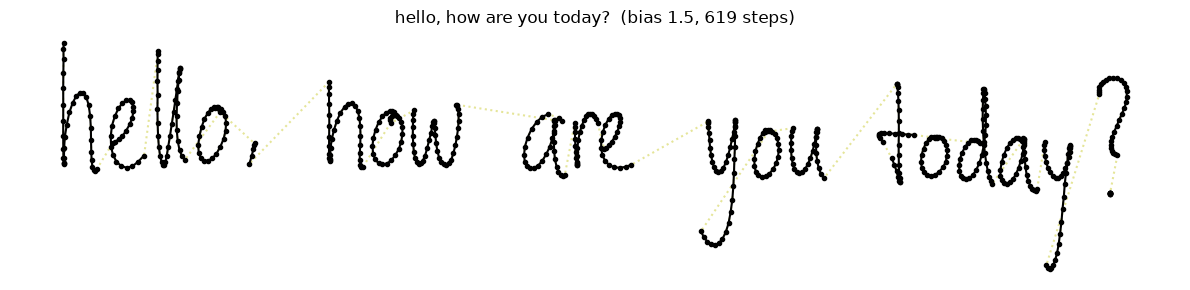

In [25]:
text = "hello, how are you today?"
bias = 1.5
seed = None

strokes, window = generate(text, bias, seed=seed)
draw_strokes(strokes, f"{text}  (bias {bias}, {len(strokes)} steps)")

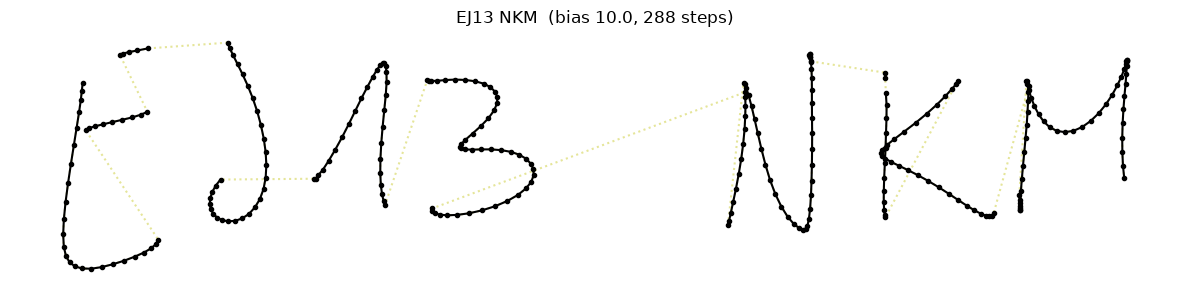

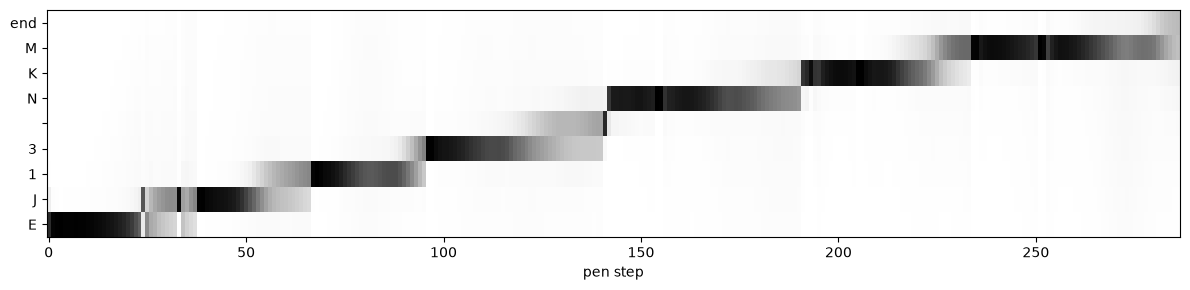

In [32]:
strokes = write("EJ13 NKM", bias=10.0)

The same text at different biases. If writing runs to `max_steps` without stopping, the window never reached the end of the text; the staircase shows where it got stuck.

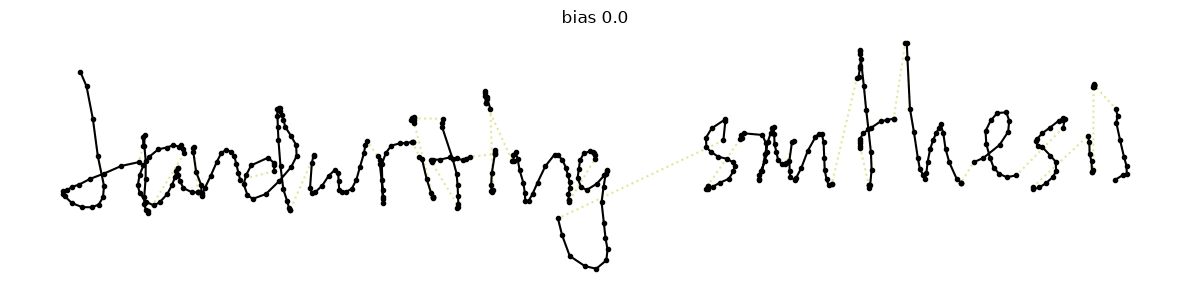

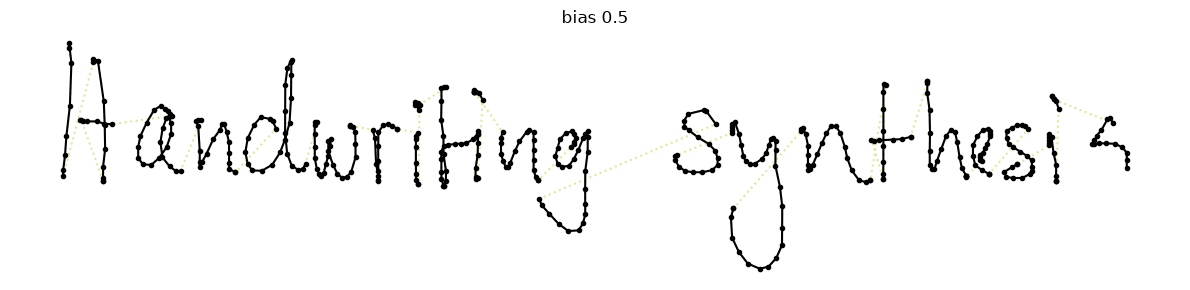

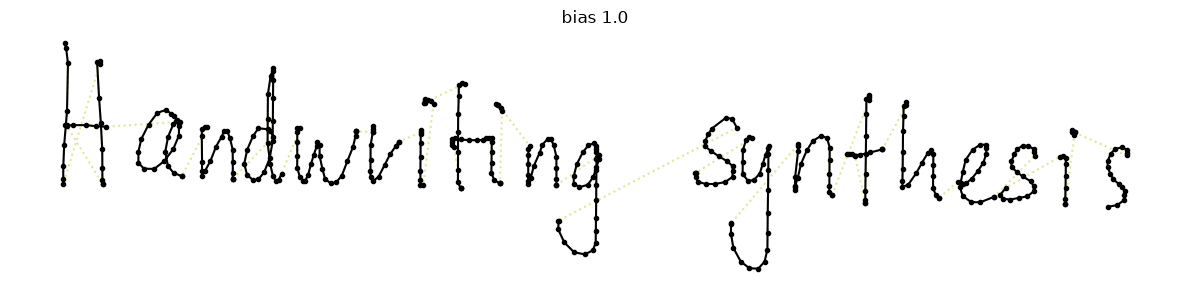

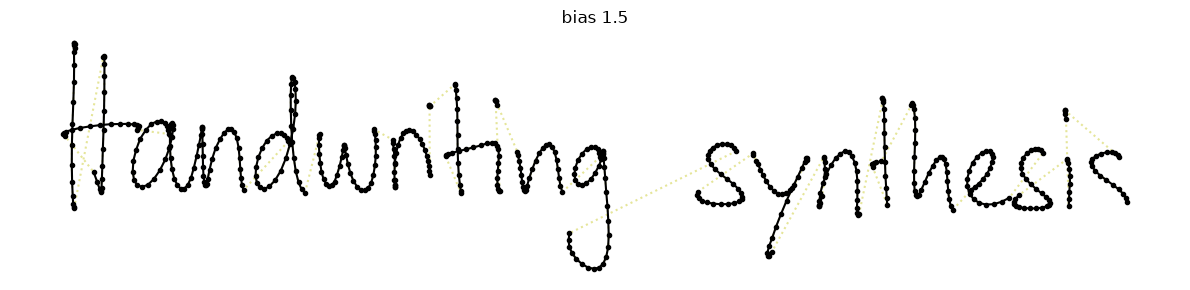

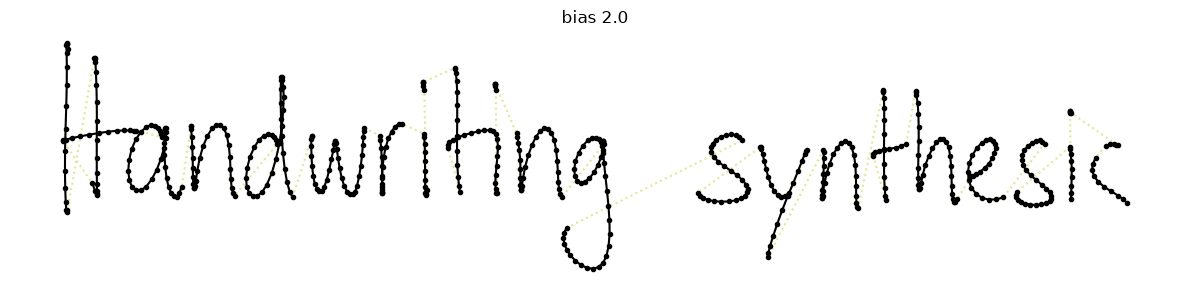

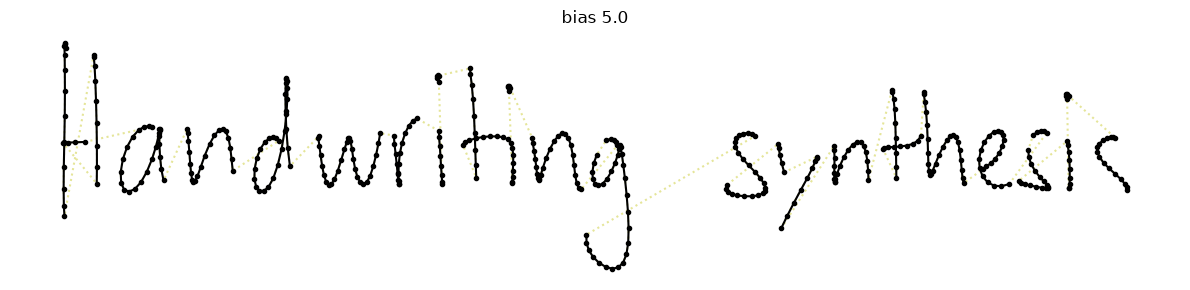

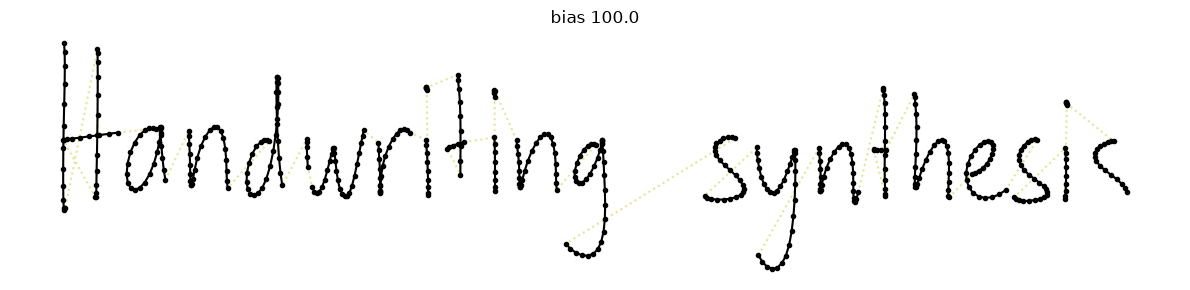

In [23]:
for bias in (0.0, 0.5, 1.0, 1.5, 2.0, 5.0, 100.0):
    strokes, _ = generate("Handwriting synthesis", bias=bias, seed=0)
    draw_strokes(strokes, f"bias {bias}")